In [26]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from fit_classes import Data
import scipy.optimize as opt
from scipy.stats import chi2

In [27]:
#foutenpropagatiefunctie
def foutenpropagatie(functie, args_symb, args, dargs):
    """
    Berekent de foutenpropagatie voor een gegeven functie.

    Args:
        functie: De functie als een sympy-expressie.
        args_symb: Een lijst van symbolische variabelen (sympy.Symbol).
        args: Een lijst of array van de numerieke waarden voor de variabelen.
        dargs: Een lijst of array van de onzekerheden in de variabelen.

    Returns:
        De berekende onzekerheid in de uitkomst van de functie.
    """
    if len(args_symb) != len(args) or len(args) != len(dargs):
        raise ValueError("De lengte van args_symb, args en dargs moet gelijk zijn.")

    variantie_termen = []
    for i in range(len(args_symb)):
        partiele_afgeleide = sp.diff(functie, args_symb[i])
        variantie_term = (partiele_afgeleide**2) * (dargs[i]**2)
        variantie_termen.append(variantie_term)

    variantie_totaal = sum(variantie_termen)
    s_func = sp.sqrt(variantie_totaal)

    # Maak een dictionary om de symbolische variabelen te vervangen door hun numerieke waarden
    substituties = {args_symb[i]: args[i] for i in range(len(args_symb))}

    # Voer de substitutie uit om de numerieke waarde van de onzekerheid te krijgen
    s = s_func.subs(substituties)

    # Converteer het resultaat naar een float
    return float(s)


In [28]:
##bandbreedte
#fig, ax = plt.subplots(figsize = (15, 5))
##realiteit
#rico1 = (13.6 - 0) / (10-4)
#rico2 = (0-13.6) / (400e3 - 200e3)
#hoogte = 13.6
#
#X1 = np.linspace(4, 10, 100)
#X2 = np.linspace(10, 200e3, 100)
#X3 = np.linspace(200e3, 400e3, 100)
#X = [X1, X2, X3]
#
#Y1 = rico1 * (X1 - 4)
#Y2 = np.full_like(X2, hoogte)
#Y3 = 13.6 + rico2 * (X3 - 200e3)
#Y = [Y1, Y2, Y3]
#
#ax.set_title('Bandbreedtes')
#ax.set_xlabel(r'$f$ [Hz]')
#ax.set_ylabel(r'$V_{max}$ [V]')
#for i in range(3):
#    ax.plot(X[i], Y[i], color = 'red')
#ax.plot(X1, Y1, color = 'red', label = 'experimenteel')
#
##verwacht
#W1 = np.linspace(0, 100, 100)
#W2 = np.linspace(100, 100e3, 100)
#W3 = np.linspace(100e3, 400e3, 100)
#W = [W1, W2, W3]
#
#Z1 = np.zeros_like(W1)
#Z2 = np.full_like(W2, hoogte)
#Z3 = np.zeros_like(W3)
#Z = [Z1, Z2, Z3]
#
#for i in range(3):
#    ax.plot(W[i], Z[i], color = 'orange', linestyle = '--')
#
#ax.vlines(4, 0, 13.6, color = 'orange', linestyle = '--', label = 'theoretisch')
#ax.vlines(100e3, 0, 13.6, color = 'orange', linestyle = '--')
#
#ax.legend()

In [29]:
#constanten berekenen
#gain
GLLE = 600
GHLE = 400
G = GLLE * GHLE
#multiplier
Vi_max = 2.8
Vo_max = 760e-3
k = Vo_max / (Vi_max**2)
#rest
kb = 1.380649e-23
T_kamer = 273+21
R = 100e3
deltaf = 100e3-100 #zou echt 100e3 moeten zijn

Vj = G**2 * k * (4 * kb * T_kamer * R * deltaf)

#fouten
#LLE en HLE maken gebruik van Non-inverting Operational Amplifiers → G = 1 + Rf/Rg (zie handleiding, 1% betrouwbaar)

def fout_GLLE():
    GLLE = 600
    return 0.01 * GLLE

def fout_GHLE():
    GHLE = 400
    return 0.01 * GHLE

def fout_G():
    GLLE, GHLE = sp.symbols('GLLE GHLE')
    GLLE_val, GHLE_val = 600, 400
    dGLLE, dGHLE = fout_GLLE(), fout_GHLE()
    args = [GLLE_val, GHLE_val]
    args_symb = [GLLE, GHLE]
    dargs = [dGLLE, dGHLE]
    G = GHLE * GLLE
    return foutenpropagatie(G, args_symb, args, dargs)

def fout_k():
    Vo, Vi = sp.symbols('Vo Vi')
    Vi_val, Vo_val = 2.8, 760e-3
    dVi , dVo = 0.4, 0.4 #2V/div / 5 onderverdelingen
    args = [Vi_val, Vo_val]
    args_symb = [Vi, Vo]
    dargs = [dVi, dVo]
    k = Vo / (Vi**2)
    return foutenpropagatie(k, args_symb, args, dargs)

def fout_deltaf():
    deltaf = 100e3-100
    return 0.05*deltaf

def fout_R():
    R = 100e3
    return 0.001 * R #manual: weerstanden zijn 0.1% nauwkeurig

def fout_T_kamer():
    return 2 #19-23 deg Celcius range (want waarom niet)

def fout_Vj(R, dR):
    Vi_max = 2.8
    Vo_max = 760e-3
    k_val = Vo_max / (Vi_max**2)
    kb = 1.380649e-23
    G, r, k, T, deltaf = sp.symbols('G r k T f')
    G_val, R_val, k_val, T_val, deltaf_val = 600*400, R, k_val, 273 + 21, 100e3-100
    dG, dk, dT, df = fout_G(), fout_k(), fout_T_kamer(), fout_deltaf()
    args = [G_val, R_val, k_val, T_val, deltaf_val]
    args_symb = [G, r, k, T, deltaf]
    dargs = [dG, dR, dk, dT, df]
    Vj = G**2 * k * (4 * kb * T_kamer * r * deltaf)
    return foutenpropagatie(Vj, args_symb, args, dargs)

print(k, fout_k())
print(Vj, fout_Vj(100e3, 0.001*100e3))


0.09693877551020409 0.05805337536950403
0.9056827700006401 0.5448733596588671


a = 8.084156076980522e-06 |b = 0.04663388369523373 |da = 1.579512211774902e-07 |db = 0.007099379389036393
chi² = 0.07616228851882857  |p = 0.972864584610715
kb = 1.2323721255643622e-23 dkb = 7.418521818462638e-24 ratio waarde = 0.8926034970252121 ratio fout = 0.5373213480372374
--------------------------------------------------------------------------------------------------------------------------
a = 1.4480553890884277e-06 |b = 0.18374186229235542 |da = 3.2502412184426384e-07 |db = 0.13335901250801901
chi² = 33.98841390179951  |p = 2.0736812707856498e-28
kb = 2.2074575018006975e-24 dkb = 1.4175376180669303e-24 ratio waarde = 0.15988549600953592 ratio fout = 0.10267183173036233
--------------------------------------------------------------------------------------------------------------------------


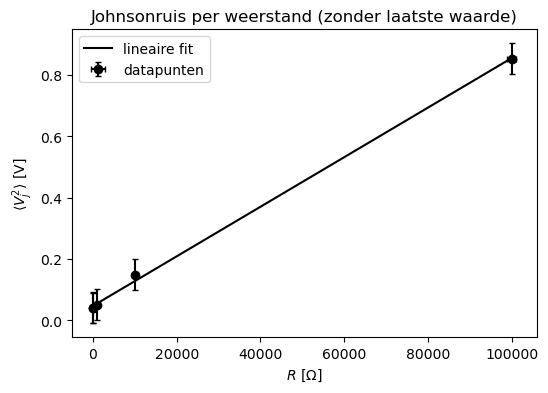

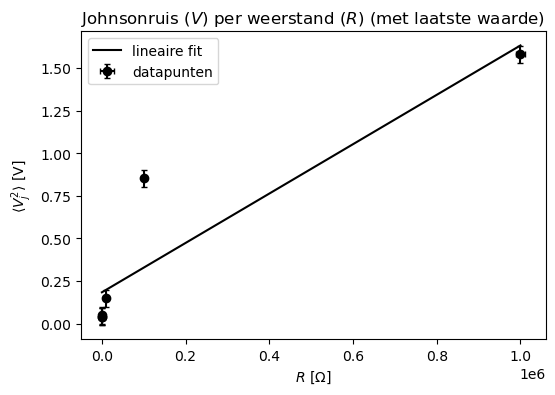

In [44]:
#boltzmannconstante
#laatste waarde weg door capaciteit (f_c = 1 / 2 pi R C)
Rin = np.array([10, 10e1, 10e2, 10e3, 10e4, 10e5])
Rin_fouten = 0.01 * Rin
V_tijdgem = np.array([39.3e-3, 40.4e-3, 50.2e-3, 148.5e-3, 0.853, 1.580])
V_fouten = np.full_like(V_tijdgem, 0.05)
#for i in range(len(Rin)):
#    V_fouten = np.append(V_fouten, fout_Vj(Rin[i], Rin_fouten[i]))

def model(x, a, b):
    return a * x + b

def model_params(params, x):
    a, b = params
    return a/1e6 * x + b

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

def fout_kb(a_val, da):
    Vi_max = 2.8
    Vo_max = 760e-3
    k_val = Vo_max / (Vi_max**2)
    a, G, k, T_kamer, deltaf = sp.symbols('a G k T_kamer deltaf')
    a_val, G_val, k_val, T_val, f_val = a_val, 600*400, k_val, 273 + 21, 100e3-100
    da, dG, dk, dT, df = da, fout_G(), fout_k(), fout_T_kamer(), fout_deltaf()
    kb = a / (G**2 * k * 4 * T_kamer * deltaf)
    args = [a_val, G_val, k_val, T_val, f_val]
    args_symb = [a, G, k, T_kamer, deltaf]
    dargs = [da, dG, dk, dT, df]
    return foutenpropagatie(kb, args_symb, args, dargs)

restfactor_rico = G**2 * k * 4 * T_kamer * deltaf

#fit ZONDER laatste datapunt
popt, pcov = opt.curve_fit(model, Rin[:-1], V_tijdgem[:-1], sigma = V_fouten[:-1])

a1 = popt[0]
b1 = popt[1]
da1 = np.sqrt(np.diag(pcov))[0]
db1 = np.sqrt(np.diag(pcov))[1]
print('a =', a1, '|b =', b1, '|da =', da1, '|db =', db1)

res = chi_sq(popt[0] * Rin[:-1] + popt[1], V_tijdgem[:-1], V_fouten[:-1], popt, Rin[:-1])
print('chi² =', res[0], ' |p =', res[1])


kb1 = a1 / restfactor_rico
dkb1 = fout_kb(a1, da1)
print('kb =', kb1, 'dkb =', dkb1, 'ratio waarde =', kb1/kb, 'ratio fout =', dkb1/kb)

#fit MET laatste datapunt
print('--------------------------------------------------------------------------------------------------------------------------')

popt, pcov = opt.curve_fit(model, Rin, V_tijdgem, sigma = V_fouten)

a2 = popt[0]
b2 = popt[1]
da2 = np.sqrt(np.diag(pcov))[0]
db2 = np.sqrt(np.diag(pcov))[1]
print('a =', a2, '|b =', b2, '|da =', da2, '|db =', db2)

res = chi_sq(popt[0] * Rin + popt[1], V_tijdgem, V_fouten, popt, Rin)
print('chi² =', res[0], ' |p =', res[1])

kb2 = a2 / restfactor_rico
dkb2 = fout_kb(a2, da2)

print('kb =', kb2, 'dkb =', dkb2, 'ratio waarde =', kb2/kb, 'ratio fout =', dkb2/kb)

#figuren

print('--------------------------------------------------------------------------------------------------------------------------')

x = [Rin[:-1], Rin]
dx = [Rin_fouten[:-1], Rin_fouten]
y = [V_tijdgem[:-1], V_tijdgem]
dy = [V_fouten[:-1], V_fouten]

rico = [a1, a2]
start = [b1, b2]

titel = [r'Johnsonruis per weerstand (zonder laatste waarde)', r'Johnsonruis ($V$) per weerstand ($R$) (met laatste waarde)']
x_label = r'$R$ [$\Omega$]'
y_label = r'$\langle V_j^2 \rangle$ [V]'


for i in range(2):
    fig, ax = plt.subplots(figsize = (6, 4))
    X = np.linspace(np.min(x[i]), np.max(x[i]), 100)
    ax.errorbar(x[i], y[i], dy[i], dx[i], fmt = 'o', capsize = 2.5, color = 'black', label = 'datapunten')
    ax.plot(X, rico[i] * X + start[i], color = 'black', label = 'lineaire fit')
    ax.set_title(titel[i])
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.legend()


In [38]:
#proef 3: likwit naaitrogjen
def fout_TN2(T_kamer, V_room, V_N2, dT, dV_room, dV_N2):
    tk, vk, vn = sp.symbols('tk vk vn')
    tn = tk * vn / vk
    s_func = sp.sqrt(sp.diff(tn, tk)**2 * dT**2 + sp.diff(tn, vk)**2 * dV_room**2 + sp.diff(tn, vn)**2 * dV_N2**2)
    s = s_func.subs([(tk, T_kamer), (vn, V_N2), (vk, V_room)])
    return s

def fout_V_echt(V, V_ruis, dV, dV_ruis):
    v, vruis = sp.symbols('v vruis')
    v_echt = v - vruis
    s_func = sp.sqrt(sp.diff(v_echt, v)**2 * dV**2 + sp.diff(v_echt, vruis)**2 * dV_ruis**2)
    s = s_func.subs([(v, V), (vruis, V_ruis)])
    return s

V_room = np.array([39.5e-3, 126.2e-3, 242.0e-3])
V_N2 = np.array([39.2e-3, 100.8e-3, 185.5e-3])

dV = np.full_like(V_room, 0.1e-3) #voor zowel room als N2

R_arr = np.array([10, 10e3, 100e3]) #zie teachspinbundel
kamerT = 21+273
V_ruis = V_N2[0] #→ in de theorie zou de voltage met een factor 1/3 vermenigvuldigen maar dat doet ze niet, redelijk zeker dat dit de achtergrond is

V_echt_room = V_room - V_ruis
V_echt_N2 = V_N2 - V_ruis

TN2 = T_kamer * V_echt_N2[1:] / V_echt_room[1:]
print(TN2)

dTN2 = np.array([])

for i in range(len(dV[1:])):
    dV_room_echt = fout_V_echt(V_room[1:][i], V_ruis, dV[1:][i], dV[0])
    dV_N2_echt = fout_V_echt(V_N2[1:][i], V_ruis, dV[1:][i], dV[0])
    dTN2 = np.append(dTN2, fout_TN2(kamerT, V_echt_room[1:][i], V_echt_N2[1:][i], 2, dV_room_echt, dV_N2_echt))

print(dTN2)
print(np.sum(TN2)/2)
print(np.std(TN2, ddof = 1))

[208.16551724 212.09171598]
[1.53238772352336 1.46478040279032]
210.12861660885534
2.7762417497706307
